# Практика 2: EDA, визуализация, пропуски и выбросы во временном ряду

**Цель:** научиться делать первичный анализ временного ряда и готовить его к моделированию.

**Данные.** ряд берётся из генератора ЛР 1 (`lab_time_series_generator.ipynb`). Генератор делает шаг 5 минут и синусоиды с периодами 1 ч и 6 ч, а в практике нужен **часовой** ряд с **суточной и недельной** сезонностью. Поэтому:

1. генерируем 56 суток с шагом 5 минут: `56 · 24 · 12 = 16 128` точек, тренд `slow_up`, дисперсия `grow`;
2. берём каждую 12-ю точку (`12 · 5 мин = 1 час`) — получаем `16 128 / 12 = 1 344` часовых значения (как показание датчика раз в час);
3. добавляем суточный цикл и «выходной» эффект (в генераторе их нет);
4. вносим дефекты: пропуски, дубликаты строк, выбросы-ошибки и одно реальное событие.

## 0. Импорт и генератор из ЛР 1

In [ ]:
import os
from datetime import datetime, date, time, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 100

# ---- генератор из ЛР 1 (без сохранения в файлы) ----
STEP = timedelta(minutes=5)
VARIANCE_MODES = ("const", "grow", "decay")
TREND_MODES = ("none", "fast_up", "slow_up", "fast_down", "slow_down")
EXTRA_TREND_MODES = ("exp", "poly", "log")
SEASONALITY_MODES = ("none", "one", "two")
PERIOD_1H = 12
PERIOD_6H = 72
TREND_DELTA = {"fast_up": 150.0, "slow_up": 30.0, "fast_down": -150.0, "slow_down": -30.0}


def make_timestamps(n_points, start=None):
    if start is None:
        start = datetime.combine(date.today(), time.min)
    return [start + i * STEP for i in range(n_points)]


def make_variance(mode, n_points):
    t = np.linspace(0.0, 1.0, n_points)
    if mode == "const":
        return np.ones(n_points)
    if mode == "grow":
        return 0.5 + 4.5 * t
    if mode == "decay":
        return 5.0 - 4.5 * t
    raise ValueError(f"Неизвестный режим дисперсии: {mode}")


def make_trend(mode, n_points):
    t = np.linspace(0.0, 1.0, n_points)
    if mode == "none":
        return np.zeros(n_points)
    if mode in TREND_DELTA:
        return TREND_DELTA[mode] * t
    if mode == "exp":
        return 100.0 * (np.exp(3.0 * t) - 1.0) / (np.exp(3.0) - 1.0)
    if mode == "poly":
        return 100.0 * (t ** 3 - 1.5 * t ** 2 + t)
    if mode == "log":
        return 100.0 * np.log1p(20.0 * t) / np.log1p(20.0)
    raise ValueError(f"Неизвестный режим тренда: {mode}")


def make_seasonality(mode, n_points):
    i = np.arange(n_points)
    if mode == "none":
        return np.zeros(n_points)
    if mode == "one":
        return 10.0 * np.sin(2 * np.pi * i / PERIOD_1H)
    if mode == "two":
        return (10.0 * np.sin(2 * np.pi * i / PERIOD_1H)
                + 20.0 * np.sin(2 * np.pi * i / PERIOD_6H))
    raise ValueError(f"Неизвестный режим сезонности: {mode}")


def generate_time_series(n_points=1000, variance="random", trend="random",
                         seasonality="random", base=100.0, noise_std=1.0, seed=None,
                         outliers=0, missing=0.0, start=None):
    rng = np.random.default_rng(seed)
    if variance == "random":
        variance = str(rng.choice(VARIANCE_MODES))
    if trend == "random":
        trend = str(rng.choice(TREND_MODES))
    if seasonality == "random":
        seasonality = str(rng.choice(SEASONALITY_MODES))

    timestamps = make_timestamps(n_points, start)
    noise = rng.normal(0.0, noise_std, n_points) * make_variance(variance, n_points)
    values = base + make_trend(trend, n_points) + make_seasonality(seasonality, n_points) + noise

    outlier_idx = []
    if outliers > 0:
        outlier_idx = rng.choice(n_points, size=min(outliers, n_points), replace=False)
        scale = np.std(values) * 3
        values[outlier_idx] += rng.choice([-1, 1], size=len(outlier_idx)) * scale
        outlier_idx = sorted(int(k) for k in outlier_idx)

    missing_idx = []
    if missing > 0:
        k = int(round(n_points * missing))
        missing_idx = rng.choice(n_points, size=k, replace=False)
        values[missing_idx] = np.nan
        missing_idx = sorted(int(k) for k in missing_idx)

    params = {"n_points": n_points, "step_minutes": 5,
              "start": timestamps[0].strftime("%Y-%m-%d %H:%M:%S"),
              "variance": variance, "trend": trend, "seasonality": seasonality,
              "base": base, "noise_std": noise_std, "seed": seed,
              "outliers": outlier_idx, "missing_count": len(missing_idx)}
    return timestamps, values, params

## 1. Подготовка данных: генерация и «грязный» CSV

Сначала собираем ряд, потом специально портим его так, как портятся реальные выгрузки: перемешанные строки, дубликаты, пропавшие строки, пустые значения, выбросы.

In [ ]:
N_DAYS = 56
N_POINTS = N_DAYS * 24 * 12           # 56 * 24 * 12 = 16128 точек по 5 минут
START = datetime(2026, 9, 7)          # понедельник 00:00

ts5, vals5, params = generate_time_series(
    n_points=N_POINTS, variance="grow", trend="slow_up", seasonality="none",
    base=100.0, noise_std=1.5, seed=42, start=START)
print(params)

s5 = pd.Series(vals5, index=pd.DatetimeIndex(ts5))
hourly = s5.iloc[::12]                # каждая 12-я точка: 12 * 5 мин = 1 час
print(f"{len(s5)} точек по 5 мин -> {len(hourly)} часовых точек "
      f"({len(s5)} / 12 = {len(s5) // 12})")

# суточный цикл и выходные (в генераторе ЛР 1 их нет)
idx = hourly.index
daily = 12.0 * np.sin(2 * np.pi * (idx.hour.to_numpy() - 9) / 24)     # амплитуда 12, максимум в 15:00
weekend = np.where(idx.dayofweek.to_numpy() >= 5, -10.0, 0.0)          # Сб/Вс на 10 ниже
y_true = hourly.to_numpy() + daily + weekend

{'n_points': 16128, 'step_minutes': 5, 'start': '2026-09-07 00:00:00', 'variance': 'grow', 'trend': 'slow_up', 'seasonality': 'none', 'base': 100.0, 'noise_std': 1.5, 'seed': 42, 'outliers': [], 'missing_count': 0}
16128 точек по 5 мин -> 1344 часовых точек (16128 / 12 = 1344)


In [ ]:
rng = np.random.default_rng(7)
n = len(y_true)
y_obs = y_true.copy()
label = np.array(["ok"] * n, dtype=object)       # ok / error / event

# реальное событие: 6 часов подряд +40 (например, акция), сутки 31, 12:00-17:00
event_idx = np.arange(30 * 24 + 12, 30 * 24 + 18)
y_obs[event_idx] += 40.0
label[event_idx] = "event"

# длинные пропуски: этих строк просто нет в файле
gap1 = np.arange(20 * 24 + 2, 20 * 24 + 20)     # 18 часов
gap2 = np.arange(42 * 24 + 8, 42 * 24 + 14)     # 6 часов

# 6 выбросов-ошибок: 5 скачков и один "ноль" (датчик вернул 0)
pool = np.setdiff1d(np.arange(24, n - 24), np.r_[event_idx, gap1, gap2])
err_idx = rng.choice(pool, size=6, replace=False)
y_obs[err_idx[:5]] += rng.choice([-1, 1], size=5) * rng.uniform(45, 70, size=5)
y_obs[err_idx[5]] = 0.0
label[err_idx] = "error"

# одиночные пропуски (3%): строка есть, значение пустое
free = np.setdiff1d(np.arange(n), np.r_[err_idx, event_idx, gap1, gap2])
single = rng.choice(free, size=int(0.03 * n), replace=False)
y_obs[single] = np.nan

raw_df = pd.DataFrame({"timestamp": hourly.index, "y": y_obs})
raw_df = raw_df.drop(index=np.r_[gap1, gap2])                   # пропавшие строки
dups = raw_df.sample(12, random_state=1)                          # 12 дубликатов
raw_df = pd.concat([raw_df, dups]).sample(frac=1, random_state=2) # перемешали
raw_df.to_csv("series.csv", index=False, date_format="%Y-%m-%d %H:%M:%S")

truth = pd.DataFrame({"label": label}, index=hourly.index)   # "ответы", нужны только для проверки в конце
print("series.csv сохранён, строк:", len(raw_df))

series.csv сохранён, строк: 1332


## 2. Шаг 1–2. Загрузка, сортировка, дубликаты, индекс и частота

In [ ]:
df = pd.read_csv("series.csv", parse_dates=["timestamp"])
print("Строк в файле:", len(df))
print(df.dtypes.to_dict())
n_dup = int(df.duplicated("timestamp").sum())
print("Дубликатов по timestamp:", n_dup)
print("Отсортирован по времени:", df["timestamp"].is_monotonic_increasing)

df = df.sort_values("timestamp").drop_duplicates("timestamp").set_index("timestamp")
print(f"После очистки: {len(df)} строк  (= {len(df) + n_dup} - {n_dup})")
df.head()

Строк в файле: 1332
{'timestamp': dtype('<M8[ns]'), 'y': dtype('float64')}
Дубликатов по timestamp: 12
Отсортирован по времени: False
После очистки: 1320 строк  (= 1332 - 12)


,y
timestamp,
2026-09-07 00:00:00,91.743256
2026-09-07 01:00:00,89.679873
2026-09-07 02:00:00,88.127987
2026-09-07 03:00:00,87.979791
2026-09-07 04:00:00,89.021006


In [ ]:
print("infer_freq:", pd.infer_freq(df.index))          # None: шаг неравномерный
steps = df.index.to_series().diff().dropna()
print(steps.value_counts())                              # видно шаги больше 1 часа

full_idx = pd.date_range(df.index.min(), df.index.max(), freq="h")
n_missing_rows = len(full_idx) - len(df)
print(f"\nОжидалось строк: {len(full_idx)}, есть: {len(df)}, "
      f"пропавших меток времени: {len(full_idx)} - {len(df)} = {n_missing_rows}")

df = df.reindex(full_idx)          # то же самое: df.asfreq("h")
df.index.name = "timestamp"
print("Частота индекса после reindex:", df.index.freqstr)

infer_freq: None
timestamp
0 days 01:00:00    1317
0 days 19:00:00       1
0 days 07:00:00       1
Name: count, dtype: int64

Ожидалось строк: 1344, есть: 1320, пропавших меток времени: 1344 - 1320 = 24
Частота индекса после reindex: h


## 3. Шаг 3. Графики

Скользящие среднее и СКО считаем по окну 24 часа (одни сутки — один полный цикл сезонности), `min_periods=12` — чтобы один пропуск не обнулял окно.

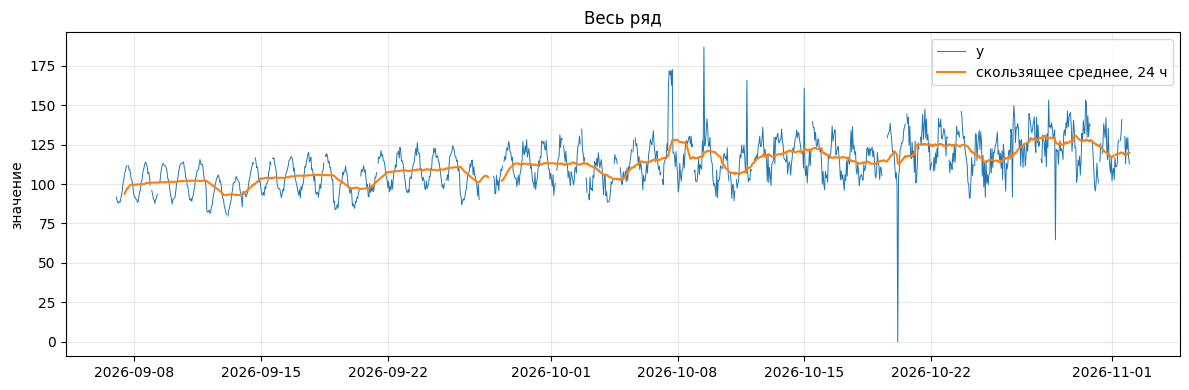

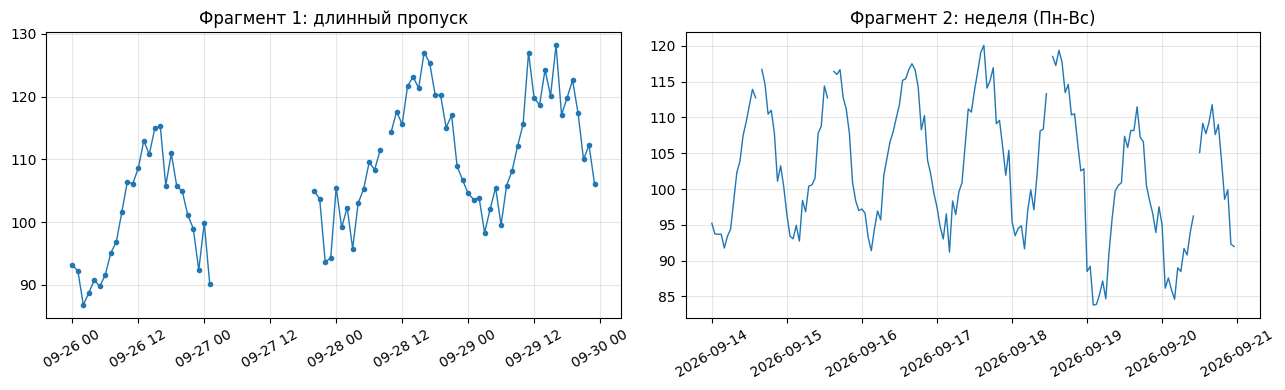

In [ ]:
df["rolling_mean"] = df["y"].rolling(24, min_periods=12).mean()
df["rolling_std"] = df["y"].rolling(24, min_periods=12).std()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.index, df["y"], lw=0.7, label="y")
ax.plot(df.index, df["rolling_mean"], lw=1.5, color="C1", label="скользящее среднее, 24 ч")
ax.set_title("Весь ряд"); ax.set_ylabel("значение"); ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
a = df.loc["2026-09-26":"2026-09-29"]          # сутки 20-22: виден длинный пропуск
axes[0].plot(a.index, a["y"], marker=".", lw=1); axes[0].set_title("Фрагмент 1: длинный пропуск")
b = df.loc["2026-09-14":"2026-09-20"]          # обычная неделя: суточный цикл и выходные
axes[1].plot(b.index, b["y"], lw=1); axes[1].set_title("Фрагмент 2: неделя (Пн-Вс)")
for ax in axes:
    ax.grid(alpha=0.3); ax.tick_params(axis="x", rotation=30)
fig.tight_layout(); plt.show()

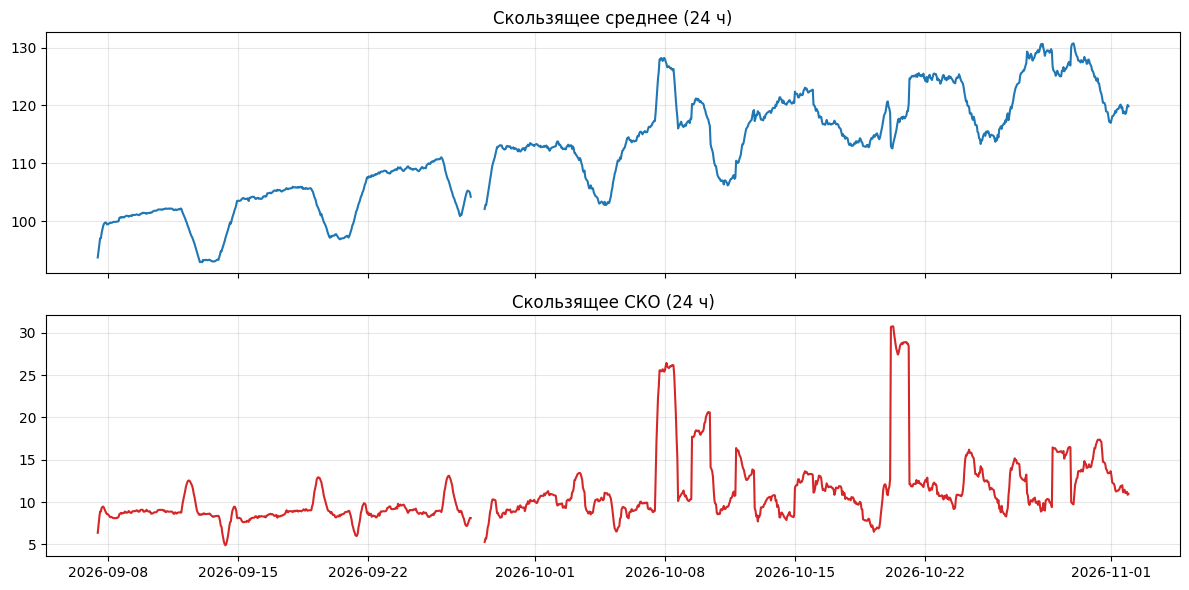

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(df.index, df["rolling_mean"]); axes[0].set_title("Скользящее среднее (24 ч)")
axes[1].plot(df.index, df["rolling_std"], color="C3"); axes[1].set_title("Скользящее СКО (24 ч)")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

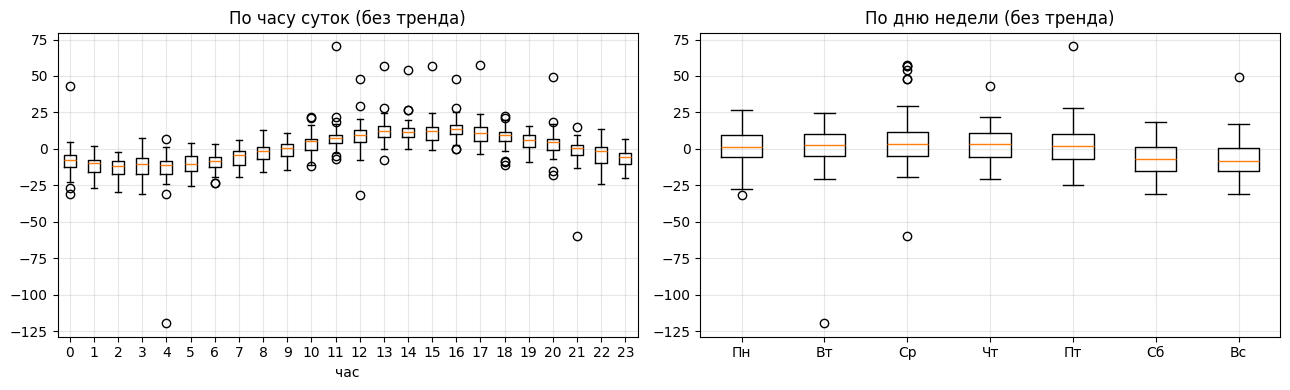

In [ ]:
# сезонные подсерии: сначала убираем тренд (вычитаем скользящее среднее за неделю = 168 ч)
weekly_mean = df["y"].rolling(168, center=True, min_periods=84).mean()
df["detr"] = df["y"] - weekly_mean

DOW = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
by_hour = [g["detr"].dropna().to_numpy() for _, g in df.groupby(df.index.hour)]
by_dow = [g["detr"].dropna().to_numpy() for _, g in df.groupby(df.index.dayofweek)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].boxplot(by_hour); axes[0].set_xticks(range(1, 25)); axes[0].set_xticklabels(range(24)); axes[0].set_title("По часу суток (без тренда)")
axes[0].set_xlabel("час")
axes[1].boxplot(by_dow); axes[1].set_xticks(range(1, 8)); axes[1].set_xticklabels(DOW); axes[1].set_title("По дню недели (без тренда)")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

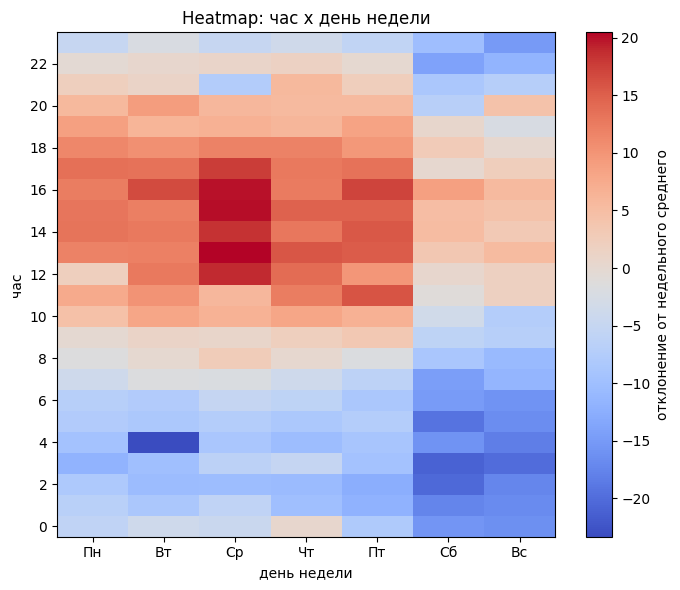

In [ ]:
# heatmap "час x день недели" (среднее значение без тренда)
heat = df.assign(hour=df.index.hour, dow=df.index.dayofweek).pivot_table(
    index="hour", columns="dow", values="detr", aggfunc="mean")

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(heat.to_numpy(), aspect="auto", cmap="coolwarm", origin="lower")
ax.set_xticks(range(7)); ax.set_xticklabels(DOW)
ax.set_yticks(range(0, 24, 2)); ax.set_yticklabels(range(0, 24, 2))
ax.set_xlabel("день недели"); ax.set_ylabel("час"); ax.set_title("Heatmap: час x день недели")
fig.colorbar(im, label="отклонение от недельного среднего"); fig.tight_layout(); plt.show()

## 4. Шаг 4. Пропуски

Считаем, сколько их, где они и нет ли длинных серий подряд.

Пропусков: 64 из 1344 = 4.76%
Серий пропусков: 42
          серий
длина, ч       
1            40
6             1
18            1

Длинные серии (>= 6 ч):


,start,end,length_h
10,2026-09-27 02:00:00,2026-09-27 19:00:00,18
28,2026-10-19 08:00:00,2026-10-19 13:00:00,6


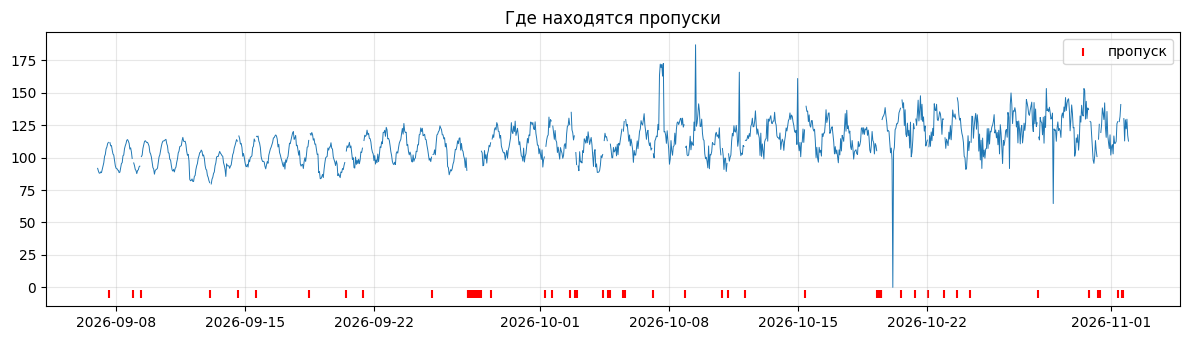

In [ ]:
miss = df["y"].isna()
print(f"Пропусков: {miss.sum()} из {len(df)} = {miss.sum() / len(df) * 100:.2f}%")

run_id = (miss != miss.shift()).cumsum()                 # номер серии подряд идущих значений
gaps = (pd.DataFrame({"t": df.index[miss], "run": run_id[miss].to_numpy()})
        .groupby("run")["t"].agg(start="min", end="max", length_h="count")
        .reset_index(drop=True))
print("Серий пропусков:", len(gaps))
print(gaps["length_h"].value_counts().sort_index().rename("серий").to_frame("серий").rename_axis("длина, ч"))
print("\nДлинные серии (>= 6 ч):")
display(gaps[gaps["length_h"] >= 6])

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(df.index, df["y"], lw=0.7)
ax.scatter(df.index[miss], np.full(miss.sum(), df["y"].min() - 5), marker="|", color="red", label="пропуск")
ax.set_title("Где находятся пропуски"); ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); plt.show()

### Сравнение методов импутации

Методы: **ffill** (последнее известное), **linear** (линейная интерполяция), **median** (медиана всего ряда), **seasonal naive** (значение ровно неделю назад, `lag = 168 ч`; если его нет — неделю вперёд, если и его нет — линейная интерполяция).

Оценка: прячем известные значения, восстанавливаем, сравниваем с настоящими.

$$MAE = \frac{1}{n}\sum_{i=1}^{n}|\hat y_i - y_i|, \qquad RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(\hat y_i - y_i)^2}$$

Четыре сценария: 5% случайных одиночных точек и блоки по 3, 12 и 24 часа (по 8 блоков).

In [ ]:
METHODS = ["ffill", "linear", "median", "seasonal_naive"]
LAG = 168


def impute(s, method):
    if method == "ffill":
        return s.ffill().bfill()
    if method == "linear":
        return s.interpolate("linear", limit_direction="both")
    if method == "median":
        return s.fillna(s.median())
    if method == "seasonal_naive":
        out = s.fillna(s.shift(LAG)).fillna(s.shift(-LAG))
        return out.fillna(s.interpolate("linear", limit_direction="both"))
    raise ValueError(method)


obs = df["y"].copy()
observed = obs.notna().to_numpy()
# точки-выбросы не берём в оценку: иначе в ошибку метода попадёт ошибка данных
# (в реальных данных здесь использовали бы результат шага 5)
clean_truth = (truth["label"] == "ok").reindex(df.index).to_numpy()
can_hide = observed & clean_truth
rng2 = np.random.default_rng(123)


def mask_single(frac=0.05):
    pos = np.flatnonzero(can_hide)
    pick = rng2.choice(pos, size=int(len(pos) * frac), replace=False)
    m = np.zeros(len(obs), bool); m[pick] = True
    return m


def mask_blocks(L, k=8):
    m = np.zeros(len(obs), bool)
    for st in rng2.choice(np.arange(200, len(obs) - L - 1), size=k, replace=False):
        m[st:st + L] = True
    return m & can_hide


def score(mask):
    res = {}
    for meth in METHODS:
        s = obs.copy(); s[mask] = np.nan
        err = (impute(s, meth)[mask] - obs[mask]).to_numpy()
        res[meth] = (np.mean(np.abs(err)), np.sqrt(np.mean(err ** 2)))
    return res


mask_one = mask_single()
scenarios = {"одиночные 5%": mask_one, "блок 3 ч": mask_blocks(3),
             "блок 12 ч": mask_blocks(12), "блок 24 ч": mask_blocks(24)}
mae = pd.DataFrame(index=METHODS, columns=scenarios, dtype=float)
rmse = mae.copy()
for name, m in scenarios.items():
    r = score(m)
    for meth in METHODS:
        mae.loc[meth, name], rmse.loc[meth, name] = r[meth]

print("Сколько точек оценивали:", {k: int(v.sum()) for k, v in scenarios.items()})
print("\nMAE:");  display(mae.round(2))
print("RMSE:"); display(rmse.round(2))

Сколько точек оценивали: {'одиночные 5%': 63, 'блок 3 ч': 23, 'блок 12 ч': 81, 'блок 24 ч': 179}

MAE:


,одиночные 5%,блок 3 ч,блок 12 ч,блок 24 ч
ffill,4.89,7.20,15.60,22.52
linear,4.42,4.84,9.67,17.71
median,13.00,9.41,10.20,10.89
seasonal_naive,5.13,5.15,6.13,6.32


RMSE:


,одиночные 5%,блок 3 ч,блок 12 ч,блок 24 ч
ffill,6.15,9.25,20.34,40.04
linear,7.42,6.66,15.12,26.72
median,15.04,13.23,12.64,13.45
seasonal_naive,6.61,6.62,7.52,11.77


In [ ]:
# ручная проверка на 3 спрятанных точках (одиночные, соседи известны)
s_hidden = obs.copy(); s_hidden[mask_one] = np.nan
pos = [i for i in np.flatnonzero(mask_one)
       if 0 < i < len(obs) - 1 and not np.isnan(s_hidden.iloc[i - 1]) and not np.isnan(s_hidden.iloc[i + 1])
       and i >= LAG and not np.isnan(s_hidden.iloc[i - LAG])][:3]

e_lin, e_sn = [], []
for i in pos:
    prev, nxt, lag, true = s_hidden.iloc[i - 1], s_hidden.iloc[i + 1], s_hidden.iloc[i - LAG], obs.iloc[i]
    lin = (prev + nxt) / 2
    e_lin.append(abs(lin - true)); e_sn.append(abs(lag - true))
    print(f"{obs.index[i]}  истинное y = {true:.2f}")
    print(f"  linear:         (y[t-1] + y[t+1]) / 2 = ({prev:.2f} + {nxt:.2f}) / 2 = {lin:.2f},  |{lin:.2f} - {true:.2f}| = {abs(lin - true):.2f}")
    print(f"  seasonal naive: y[t-168] = {lag:.2f},  |{lag:.2f} - {true:.2f}| = {abs(lag - true):.2f}")

print(f"\nMAE linear (3 точки)         = ({' + '.join(f'{e:.2f}' for e in e_lin)}) / 3 = {np.mean(e_lin):.2f}")
print(f"MAE seasonal naive (3 точки) = ({' + '.join(f'{e:.2f}' for e in e_sn)}) / 3 = {np.mean(e_sn):.2f}")

2026-09-14 17:00:00  истинное y = 114.68
  linear:         (y[t-1] + y[t+1]) / 2 = (116.72 + 110.47) / 2 = 113.60,  |113.60 - 114.68| = 1.08
  seasonal naive: y[t-168] = 109.06,  |109.06 - 114.68| = 5.62
2026-09-14 20:00:00  истинное y = 107.87
  linear:         (y[t-1] + y[t+1]) / 2 = (111.01 + 101.08) / 2 = 106.04,  |106.04 - 107.87| = 1.82
  seasonal naive: y[t-168] = 102.81,  |102.81 - 107.87| = 5.06
2026-09-15 21:00:00  истинное y = 100.93
  linear:         (y[t-1] + y[t+1]) / 2 = (107.76 + 98.37) / 2 = 103.06,  |103.06 - 100.93| = 2.13
  seasonal naive: y[t-168] = 99.36,  |99.36 - 100.93| = 1.58

MAE linear (3 точки)         = (1.08 + 1.82 + 2.13) / 3 = 1.68
MAE seasonal naive (3 точки) = (5.62 + 5.06 + 1.58) / 3 = 4.08


### Итоговая импутация

По таблице выше выбираем правило: **короткие серии (≤ 3 ч) — линейная интерполяция, длинные — seasonal naive.** Проверьте, что оно соответствует вашей таблице MAE; если результаты изменились (другой seed), поправьте порог `MAX_SHORT`.

Осталось NaN: 0 | заполнено точек: 64


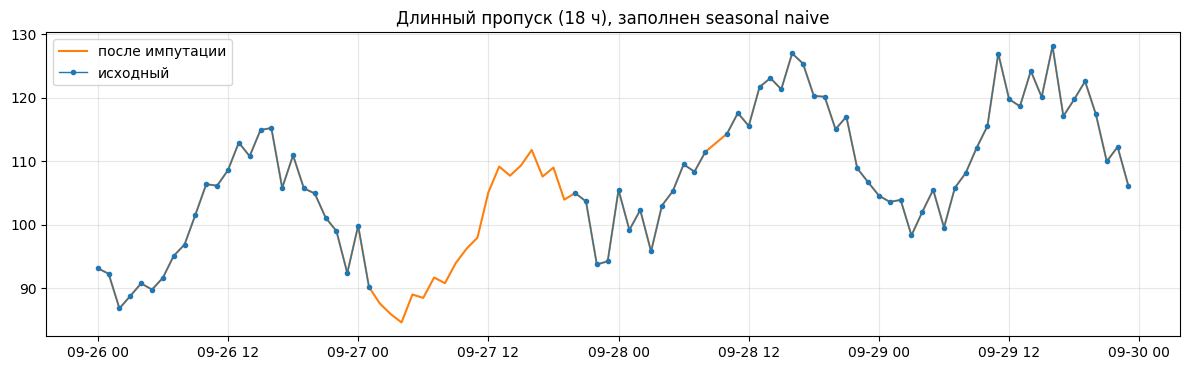

In [ ]:
MAX_SHORT = 3


def fill_hybrid(s, max_short=MAX_SHORT):
    m = s.isna()
    rid = (m != m.shift()).cumsum()
    run_len = m.groupby(rid).transform("sum")            # длина серии пропусков для каждой точки
    lin, sn = impute(s, "linear"), impute(s, "seasonal_naive")
    out = s.copy()
    out[m & (run_len <= max_short)] = lin[m & (run_len <= max_short)]
    out[m & (run_len > max_short)] = sn[m & (run_len > max_short)]
    return out


df["y_filled"] = fill_hybrid(df["y"])
df["is_imputed"] = df["y"].isna()
print("Осталось NaN:", int(df["y_filled"].isna().sum()), "| заполнено точек:", int(df["is_imputed"].sum()))

a = df.loc["2026-09-26":"2026-09-29"]
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(a.index, a["y_filled"], color="C1", lw=1.5, label="после импутации")
ax.plot(a.index, a["y"], color="C0", marker=".", lw=1, label="исходный")
ax.set_title("Длинный пропуск (18 ч), заполнен seasonal naive"); ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); plt.show()

## 5. Шаг 5. Выбросы

Выбросы ищем на исходном ряде с пропусками (NaN методы пропускают сами). Три метода:

- **IQR:** $IQR = Q_3 - Q_1$, выброс, если $y < Q_1 - 1.5\,IQR$ или $y > Q_3 + 1.5\,IQR$;
- **z-score:** $z = (y-\mu)/\sigma$, выброс при $|z|>3$;
- **rolling median / MAD** (модифицированный z-score): $M_i = 0{,}6745\,(r_i - \mathrm{med}_i)/\mathrm{MAD}_i$, выброс при $|M_i|>thr$ (окно 49 ч = 2 суток, $thr = 4{,}5$; ниже показано, как результат зависит от этих параметров).

В ряде есть тренд и сезонность, поэтому IQR и z-score применяем в двух вариантах: к **сырому** ряду и к **остатку** (ряд минус недельная медиана минус профиль «день недели × час»).

In [ ]:
y = df["y"]
trend_med = y.rolling(168, center=True, min_periods=84).median()
detr = y - trend_med
profile = detr.groupby([df.index.dayofweek, df.index.hour]).transform("median")
df["resid"] = detr - profile
resid = df["resid"]


def iqr_flags(s, k=1.5, name=""):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    print(f"[IQR {name}] IQR = Q3 - Q1 = {q3:.2f} - {q1:.2f} = {iqr:.2f}")
    print(f"   нижняя граница = Q1 - 1.5*IQR = {q1:.2f} - 1.5*{iqr:.2f} = {lo:.2f}")
    print(f"   верхняя граница = Q3 + 1.5*IQR = {q3:.2f} + 1.5*{iqr:.2f} = {hi:.2f}")
    return (s < lo) | (s > hi)


def z_flags(s, thr=3, name=""):
    mu, sd = s.mean(), s.std()
    print(f"[z-score {name}] mu = {mu:.2f}, sigma = {sd:.2f}; граница mu ± 3*sigma = {mu:.2f} ± {3 * sd:.2f}"
          f" -> [{mu - thr * sd:.2f}; {mu + thr * sd:.2f}]")
    return ((s - mu) / sd).abs() > thr


def mad_flags(s, win=49, thr=4.5):
    med = s.rolling(win, center=True, min_periods=win // 2 + 1).median()
    mad = (s - med).abs().rolling(win, center=True, min_periods=win // 2 + 1).median()
    mz = 0.6745 * (s - med) / mad
    return mz.abs() > thr


df["outlier_iqr_raw"] = iqr_flags(y, name="сырой ряд")
df["outlier_z_raw"] = z_flags(y, name="сырой ряд")
df["outlier_iqr_resid"] = iqr_flags(resid, name="остаток")
df["outlier_z_resid"] = z_flags(resid, name="остаток")
df["outlier_mad"] = mad_flags(resid)

[IQR сырой ряд] IQR = Q3 - Q1 = 121.43 - 102.08 = 19.35
   нижняя граница = Q1 - 1.5*IQR = 102.08 - 1.5*19.35 = 73.06
   верхняя граница = Q3 + 1.5*IQR = 121.43 + 1.5*19.35 = 150.46
[z-score сырой ряд] mu = 112.28, sigma = 14.72; граница mu ± 3*sigma = 112.28 ± 44.16 -> [68.12; 156.44]
[IQR остаток] IQR = Q3 - Q1 = 2.20 - -1.99 = 4.19
   нижняя граница = Q1 - 1.5*IQR = -1.99 - 1.5*4.19 = -8.27
   верхняя граница = Q3 + 1.5*IQR = 2.20 + 1.5*4.19 = 8.49
[z-score остаток] mu = 0.23, sigma = 6.97; граница mu ± 3*sigma = 0.23 ± 20.90 -> [-20.67; 21.13]


In [ ]:
# так как ряд синтетический, знаем, что на самом деле есть что
lab = truth["label"].reindex(df.index)
rows = []
for col in ["outlier_iqr_raw", "outlier_z_raw", "outlier_iqr_resid", "outlier_z_resid", "outlier_mad"]:
    f = df[col]
    rows.append({"метод": col.replace("outlier_", ""),
                 "помечено": int(f.sum()),
                 "ошибки найдены (из 6)": int((f & (lab == "error")).sum()),
                 "точки события (из 6)": int((f & (lab == "event")).sum()),
                 "ложные срабатывания": int((f & (lab == "ok")).sum())})
summary = pd.DataFrame(rows).set_index("метод")
display(summary)

,помечено,ошибки найдены (из 6),точки события (из 6),ложные срабатывания
метод,,,,
iqr_raw,14,5,6,3
z_raw,11,5,6,0
iqr_resid,103,6,6,91
z_resid,12,6,6,0
mad,12,6,6,0


In [ ]:
# чувствительность rolling MAD к окну и порогу
rows = []
for win in (25, 49):
    for thr in (3.5, 4.5):
        f = mad_flags(resid, win=win, thr=thr)
        rows.append({"окно, ч": win, "порог": thr, "помечено": int(f.sum()),
                     "ошибки (из 6)": int((f & (lab == "error")).sum()),
                     "точки события (из 6)": int((f & (lab == "event")).sum()),
                     "ложные срабатывания": int((f & (lab == "ok")).sum())})
display(pd.DataFrame(rows))

,"окно, ч",порог,помечено,ошибки (из 6),точки события (из 6),ложные срабатывания
0,25,3.5,29,6,6,17
1,25,4.5,18,6,6,6
2,49,3.5,27,6,6,15
3,49,4.5,12,6,6,0


,start,length_h,mean_dev,вердикт,на самом деле
0,2026-10-07 12:00:00,6,41.6,реальное событие (серия подряд),event
1,2026-10-09 11:00:00,1,63.7,ошибка/сбой (одиночный скачок),error
2,2026-10-11 20:00:00,1,53.0,ошибка/сбой (одиночный скачок),error
3,2026-10-15 00:00:00,1,47.3,ошибка/сбой (одиночный скачок),error
4,2026-10-20 04:00:00,1,-110.6,ошибка/сбой (одиночный скачок),error
5,2026-10-26 12:00:00,1,-39.5,ошибка/сбой (одиночный скачок),error
6,2026-10-28 21:00:00,1,-60.0,ошибка/сбой (одиночный скачок),error


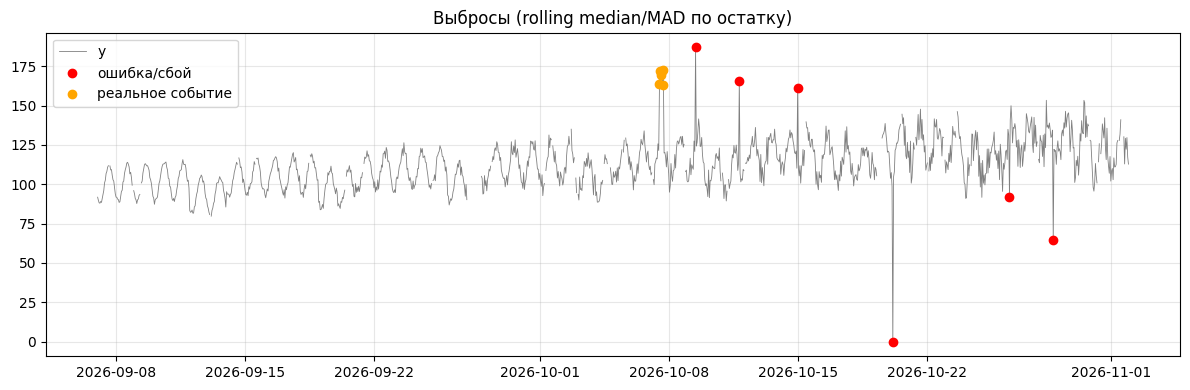

In [ ]:
# эпизоды выбросов по лучшему методу (rolling MAD по остатку): ошибка или реальное событие?
fl = df["outlier_mad"]
ep = (fl != fl.shift()).cumsum()
eps = (pd.DataFrame({"t": df.index[fl], "ep": ep[fl].to_numpy(), "dev": resid[fl].to_numpy()})
       .groupby("ep").agg(start=("t", "min"), length_h=("t", "count"), mean_dev=("dev", "mean"))
       .reset_index(drop=True))
eps["mean_dev"] = eps["mean_dev"].round(1)
eps["вердикт"] = np.where(eps["length_h"] >= 3, "реальное событие (серия подряд)", "ошибка/сбой (одиночный скачок)")
eps["на самом деле"] = lab.loc[eps["start"]].to_numpy()
display(eps)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.index, df["y"], lw=0.6, color="gray", label="y")
single_e = eps[eps["length_h"] < 3]["start"]
ax.scatter(single_e, df.loc[single_e, "y"], color="red", zorder=3, label="ошибка/сбой")
for _, r in eps[eps["length_h"] >= 3].iterrows():
    seg = df.loc[r["start"]: r["start"] + pd.Timedelta(hours=int(r["length_h"]) - 1), "y"]
    ax.scatter(seg.index, seg, color="orange", zorder=3, label="реальное событие")
h, l = ax.get_legend_handles_labels(); u = dict(zip(l, h)); ax.legend(u.values(), u.keys())
ax.set_title("Выбросы (rolling median/MAD по остатку)"); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

**Как отличать ошибку от события.** Одиночный скачок на 1 час, особенно физически невозможное значение (датчик вернул `0`), — вероятнее всего **ошибка**: такие точки стоит заменить на NaN и заново заполнить. Серия из нескольких часов подряд с гладким подъёмом и спадом — вероятнее **реальное событие** (акция, всплеск трафика): его удалять нельзя, лучше пометить признаком. В реальных данных решение принимают по контексту (журнал работ, календарь акций, показания соседних датчиков); здесь «правильный ответ» известен только потому, что ряд синтетический.

Ошибок заменено: 6 | точек в событиях (оставлены, помечены is_event): 6


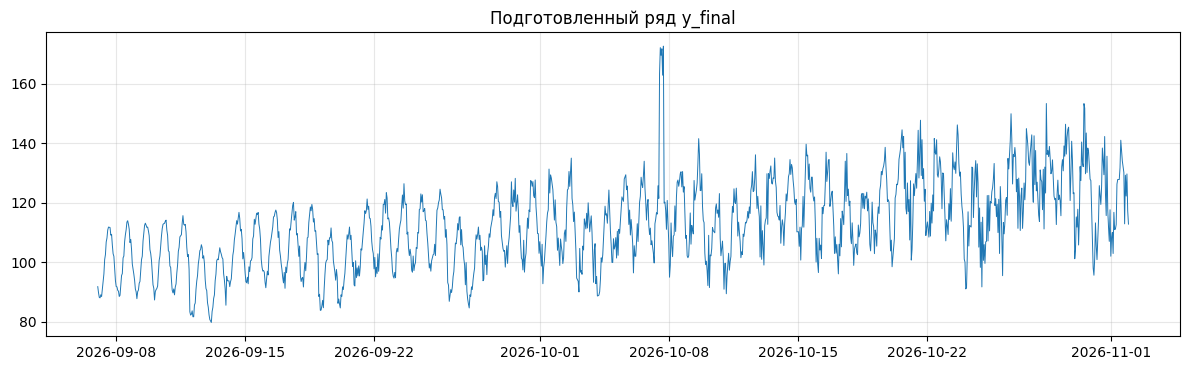

In [ ]:
# подготовка к моделированию: ошибки -> NaN -> повторная импутация, события оставляем
bad = np.zeros(len(df), bool)
for st in eps.loc[eps["length_h"] < 3, "start"]:
    bad[df.index.get_loc(st)] = True
y_final_src = df["y"].copy(); y_final_src[bad] = np.nan
df["y_final"] = fill_hybrid(y_final_src)
df["is_event"] = False
for _, r in eps[eps["length_h"] >= 3].iterrows():
    df.loc[r["start"]: r["start"] + pd.Timedelta(hours=int(r["length_h"]) - 1), "is_event"] = True

print("Ошибок заменено:", int(bad.sum()), "| точек в событиях (оставлены, помечены is_event):", int(df["is_event"].sum()))
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(df.index, df["y_final"], lw=0.7)
ax.set_title("Подготовленный ряд y_final"); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()
df[["y", "y_filled", "y_final", "is_imputed", "is_event"]].to_csv("series_clean.csv")

## 6. Шаг 6. Выводы

In [ ]:
yf = df["y_final"]
d = df.index.normalize()
w1 = yf[d < d.min() + pd.Timedelta(days=7)].mean()
w8 = yf[d >= d.min() + pd.Timedelta(days=49)].mean()
slope = (w8 - w1) / 49          # середины первой и последней недели отстоят на 49 суток
print("1) ТРЕНД")
print(f"   среднее 1-й недели = {w1:.2f}, 8-й недели = {w8:.2f}")
print(f"   наклон = ({w8:.2f} - {w1:.2f}) / 49 сут = {slope:.3f} ед./сутки  "
      f"(ожидание: 30 / 56 = {30 / 56:.3f})")

prof_h = df["detr"].groupby(df.index.hour).median()
amp = (prof_h.max() - prof_h.min()) / 2
wd = df.loc[df.index.dayofweek < 5, "detr"].median()
we = df.loc[df.index.dayofweek >= 5, "detr"].median()
print("\n2) СЕЗОННОСТЬ")
print(f"   суточная амплитуда = (макс - мин) / 2 = ({prof_h.max():.2f} - ({prof_h.min():.2f})) / 2 = {amp:.2f}  (ожидание: 12)")
print(f"   выходные ниже будней на {wd:.2f} - ({we:.2f}) = {wd - we:.2f}  (ожидание: 10)")

ok = ~df["outlier_mad"]
day0 = d.min()
def week_sd(k):                      # k = номер недели с нуля; края ряда не берём (там окно медианы неполное)
    m = (d >= day0 + pd.Timedelta(days=7 * k)) & (d < day0 + pd.Timedelta(days=7 * (k + 1))) & ok
    return resid[m].std()
def sigma_expected(k):               # sigma(t) = noise_std * (0.5 + 4.5 * t), t - середина недели в долях ряда
    t = (7 * k + 3.5) / 56
    return 1.5 * (0.5 + 4.5 * t), t
s2, s7 = week_sd(1), week_sd(6)
e2, t2 = sigma_expected(1); e7, t7 = sigma_expected(6)
print("\n3) СДВИГ ДИСПЕРСИИ (сравниваем 2-ю и 7-ю недели, чтобы не брать края ряда)")
print(f"   измеренное СКО остатка: 2-я неделя = {s2:.2f}, 7-я неделя = {s7:.2f}, отношение = {s7:.2f} / {s2:.2f} = {s7 / s2:.1f}")
print(f"   ожидание по генератору: 2-я = 1.5 * (0.5 + 4.5 * {t2:.3f}) = {e2:.2f}, 7-я = 1.5 * (0.5 + 4.5 * {t7:.3f}) = {e7:.2f}, "
      f"отношение = {e7 / e2:.1f}")

n_all = len(df)
n_miss = int(df["is_imputed"].sum())
print("\n4) КАЧЕСТВО ДАННЫХ")
print(f"   дубликатов строк: {n_dup}; пропавших меток времени: {n_missing_rows}")
print(f"   пропусков в значениях: {n_miss} из {n_all} = {n_miss / n_all * 100:.2f}%; самая длинная серия = {int(gaps['length_h'].max())} ч")

print("\n5) ВЫБРОСЫ")
print(f"   rolling MAD нашёл {int(df['outlier_mad'].sum())} точек в {len(eps)} эпизодах: "
      f"{int((eps['length_h'] < 3).sum())} одиночных (ошибки) и {int((eps['length_h'] >= 3).sum())} серия(и) подряд (событие)")
sm = summary
print(f"   сравнение методов: IQR по сырому ряду дал {sm.loc['iqr_raw', 'ложные срабатывания']} ложных, z-score по сырому ряду нашёл "
      f"{sm.loc['z_raw', 'ошибки найдены (из 6)']} из 6 ошибок; IQR по остатку дал {sm.loc['iqr_resid', 'ложные срабатывания']} ложных "
      f"(дисперсия растёт, единая граница не подходит); rolling MAD: {sm.loc['mad', 'ложные срабатывания']} ложных")

1) ТРЕНД
   среднее 1-й недели = 98.86, 8-й недели = 125.58
   наклон = (125.58 - 98.86) / 49 сут = 0.545 ед./сутки  (ожидание: 30 / 56 = 0.536)

2) СЕЗОННОСТЬ
   суточная амплитуда = (макс - мин) / 2 = (13.40 - (-11.82)) / 2 = 12.61  (ожидание: 12)
   выходные ниже будней на 2.59 - (-7.50) = 10.09  (ожидание: 10)

3) СДВИГ ДИСПЕРСИИ (сравниваем 2-ю и 7-ю недели, чтобы не брать края ряда)
   измеренное СКО остатка: 2-я неделя = 1.88, 7-я неделя = 6.17, отношение = 6.17 / 1.88 = 3.3
   ожидание по генератору: 2-я = 1.5 * (0.5 + 4.5 * 0.188) = 2.02, 7-я = 1.5 * (0.5 + 4.5 * 0.812) = 6.23, отношение = 3.1

4) КАЧЕСТВО ДАННЫХ
   дубликатов строк: 12; пропавших меток времени: 24
   пропусков в значениях: 64 из 1344 = 4.76%; самая длинная серия = 18 ч

5) ВЫБРОСЫ
   rolling MAD нашёл 12 точек в 7 эпизодах: 6 одиночных (ошибки) и 1 серия(и) подряд (событие)
   сравнение методов: IQR по сырому ряду дал 3 ложных, z-score по сырому ряду нашёл 5 из 6 ошибок; IQR по остатку дал 91 ложных (дисперси

1. Тренд есть, он восходящий и примерно линейный.
Среднее значение выросло с 98,86 в 1-ю неделю до 125,58 в 8-ю. Середины этих недель отстоят на 49 суток, поэтому наклон равен (125,58 − 98,86) / 49 = 0,545 ед./сутки, то есть около 0,545 · 7 ≈ 3,8 ед. в неделю. За все 56 суток рост составляет 0,545 · 56 ≈ 30,5 ед. Это подтверждает и график скользящего среднего. Тренд надо учитывать при моделировании, например через дифференцирование или отдельную компоненту.

2. Есть суточная и недельная сезонность.
Суточный цикл виден на графиках, на боксплотах по часам и на heatmap. Амплитуда равна (13,40 − (−11,82)) / 2 = 12,61 ед. Недельная сезонность видна по дням недели: в выходные значения ниже, чем в будни, на 2,59 − (−7,50) = 10,09 ед. Значит, модели нужны оба периода: 24 часа и 168 часов (7 · 24).

3. Есть сдвиг дисперсии: разброс со временем растёт.
Ряд неоднороден по разбросу (гетероскедастичность). СКО остатка выросло с 1,88 (2-я неделя) до 6,17 (7-я неделя), то есть в 6,17 / 1,88 ≈ 3,3 раза. Это видно и по скользящему СКО. Из-за такого роста единые границы IQR и z-score плохо подходят к этому ряду: по остатку IQR дал 91 ложное срабатывание, а метод rolling MAD, который считает разброс локально, дал 0. Для моделирования стоит рассмотреть преобразование, стабилизирующее дисперсию (например, логарифм), или модель с меняющейся дисперсией.

4. Есть проблемы качества данных.

- Дубликаты и порядок. В файле 12 дубликатов по времени, строки шли не по порядку. После sort_values и drop_duplicates осталось 1 332 − 12 = 1 320 строк.
- Пропавшие строки. До полного часового индекса не хватало 1 344 − 1 320 = 24 меток времени, это две длинные серии: 18 + 6 = 24 часа.
- Пустые значения. Всего значений-пропусков 64 из 1 344, то есть 64 / 1 344 = 4,76 %. Из них 24 пришли из пропавших строк и 40 это одиночные пустые значения (64 − 24 = 40).
- Длинные серии. Серий пропусков 42: 40 одиночных, одна на 6 часов и одна на 18 часов.
